# 04.1 · Modelagem — o cotovelo de cada algoritmo

**CRISP-DM fase 4 — modelagem** · Turismo e Hotelaria

---

Entrada: a matriz pré-processada do notebook [`03-preparacao`](03-preparacao.ipynb),
com variáveis quantitativas normalizadas e categorias nominais codificadas.

Cada algoritmo é treinado para diferentes valores de *k* ou de seus parâmetros e
gera curvas de peso e silhueta. A análise usa uma amostra controlada de reservas,
pois a base completa tem 119.390 registros.

| Algoritmo | Parâmetro | Peso | Silhueta |
|---|---|---|---|
| K-Means | nº de centroides | inércia | euclidiana |
| K-Means Manhattan | nº de centros | soma das distâncias L1 | euclidiana |
| K-Means Mahalanobis | nº de centroides | inércia após branqueamento | euclidiana |
| GMM | nº de componentes | −log-verossimilhança | euclidiana |
| DBSCAN | raio `eps` | soma dos quadrados intra-grupo | euclidiana |

A silhueta é calculada no mesmo espaço pré-processado para permitir a comparação
entre os algoritmos.

In [40]:
import warnings
warnings.filterwarnings("ignore")

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.spatial.distance import cdist
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline

K = list(range(1, 6))
FAIXA = (2, 5)
SILHUETA_MINIMA = 0.25
RUIDO_MAXIMO = 0.20
GRUPO_MAXIMO = 0.90

## 1 · Dados e distâncias

In [41]:
X = pd.read_csv(
    "../data/processed/hotel_bookings_preprocessed.csv",
    sep=";",
).to_numpy(dtype=float)

N = len(X)

RNG = np.random.default_rng(42)
INDICES = RNG.choice(
    N,
    size=min(10_000, N),
    replace=False,
)

X_AMOSTRA = X[INDICES]
N_AMOSTRA = len(X_AMOSTRA)

X.shape

(119390, 98)

**Mahalanobis** desconta a correlação entre as variáveis. Ela é a distância euclidiana depois de **branquear** os dados: rotacionar para os componentes principais e dividir cada um pelo próprio desvio-padrão. Por isso, rodar o K-Means no espaço branqueado **é** rodar o K-Means com Mahalanobis.

O one-hot gera direções de variância nula (as colunas de uma nominal somam 1). Elas ficam fora, o que equivale a usar a pseudo-inversa.

In [42]:
# O branqueamento de Mahalanobis é aplicado na função ajustar_mahalanobis.
# Não calculamos matrizes completas de covariância ou distância nesta etapa.

print("Transformação de Mahalanobis será aplicada durante o ajuste do modelo.")

Transformação de Mahalanobis será aplicada durante o ajuste do modelo.


## 2 · Funções de apoio

In [43]:
def silhueta(X, rotulos):
    validos = rotulos >= 0

    if len(np.unique(rotulos[validos])) < 2:
        return np.nan

    return silhouette_score(
        X[validos],
        rotulos[validos],
        metric="euclidean",
    )


def soma_quadrados(X, rotulos):
    total = 0.0

    for grupo in np.unique(rotulos):
        membros = X[rotulos == grupo]

        if len(membros) == 0:
            continue

        centro = membros.mean(axis=0)
        total += ((membros - centro) ** 2).sum()

    return total


def cotovelo(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if len(np.unique(y)) < 3:
        return None

    px = (x - x.min()) / np.ptp(x)
    py = (y - y.min()) / np.ptp(y)

    dx = px[-1] - px[0]
    dy = py[-1] - py[0]

    distancia = np.abs(
        dy * (px - px[0]) - dx * (py - py[0])
    ) / np.hypot(dx, dy)

    return x[distancia.argmax()]

In [44]:
def kmedianas(X, k, n_init=10, max_iter=100, seed=42):
    # K-Means com régua Manhattan: atribui pela L1 e o centro vira a mediana (que minimiza a soma L1).
    rng = np.random.default_rng(seed)
    melhor = (None, np.inf)
    for _ in range(n_init):                                            # várias partidas; fica a de menor custo
        centros = X[rng.choice(len(X), k, replace=False)]              # centros iniciais sorteados entre os imóveis
        for _ in range(max_iter):
            rotulos = cdist(X, centros, 'cityblock').argmin(axis=1)    # cada imóvel vai ao centro mais próximo em L1
            novos = np.array([np.median(X[rotulos == g], axis=0) if (rotulos == g).any() else centros[g]
                              for g in range(k)])                      # novo centro = mediana do grupo
            if np.allclose(novos, centros):                            # centros parados: convergiu
                break
            centros = novos
        dist = cdist(X, centros, 'cityblock')
        if dist.min(axis=1).sum() < melhor[1]:
            melhor = (dist.argmin(axis=1), dist.min(axis=1).sum())     # rótulos e soma das distâncias L1
    return melhor


## 3 · Os algoritmos

Cada função recebe o valor varrido (*k* ou o parâmetro) e devolve `(rótulos, peso)`.

- **GMM:** usa `reg_covar=1e-3` para estabilizar as variâncias das variáveis codificadas.
- **K-Means Mahalanobis:** aplica PCA com branqueamento antes do agrupamento.
- **DBSCAN:** usa um parâmetro de densidade; o número de grupos emerge do raio utilizado.
- **K-Means Manhattan:** usa distância L1 e centros atualizados pela mediana.

In [45]:
def ajustar_kmeans(k):
    modelo = KMeans(
        n_clusters=k,
        n_init=3,
        max_iter=100,
        random_state=42,
    ).fit(X_AMOSTRA)

    return modelo.labels_, modelo.inertia_


def ajustar_mahalanobis(k):
    componentes = min(X_AMOSTRA.shape[1], 30)

    modelo = Pipeline(
        [
            (
                "pca",
                PCA(
                    n_components=componentes,
                    whiten=True,
                    random_state=42,
                ),
            ),
            (
                "kmeans",
                KMeans(
                    n_clusters=k,
                    n_init=3,
                    max_iter=100,
                    random_state=42,
                ),
            ),
        ]
    ).fit(X_AMOSTRA)

    kmeans = modelo.named_steps["kmeans"]
    return kmeans.labels_, kmeans.inertia_


def ajustar_gmm(k):
    modelo = GaussianMixture(
        n_components=k,
        covariance_type="diag",
        reg_covar=1e-3,
        max_iter=100,
        random_state=42,
    ).fit(X_AMOSTRA)

    return modelo.predict(X_AMOSTRA), -modelo.score(X_AMOSTRA) * N_AMOSTRA


def ajustar_dbscan(eps):
    modelo = DBSCAN(
        eps=eps,
        min_samples=10,
        n_jobs=-1,
    )
    rotulos = modelo.fit_predict(X_AMOSTRA)
    validos = rotulos >= 0
    peso = (
        soma_quadrados(X_AMOSTRA[validos], rotulos[validos])
        if validos.any()
        else 0.0
    )
    return rotulos, peso

### Escala do DBSCAN

O DBSCAN tem um diagnóstico próprio: a curva k-distância, que mostra a distância
de cada reserva ao seu `min_samples`-ésimo vizinho. Os raios testados são percentis
dessa curva, calculada na amostra controlada.

Amostra: 10,000
Raios: [2.253, 2.077, 1.972, 1.719, 1.467]
Eps do joelho: 2.132


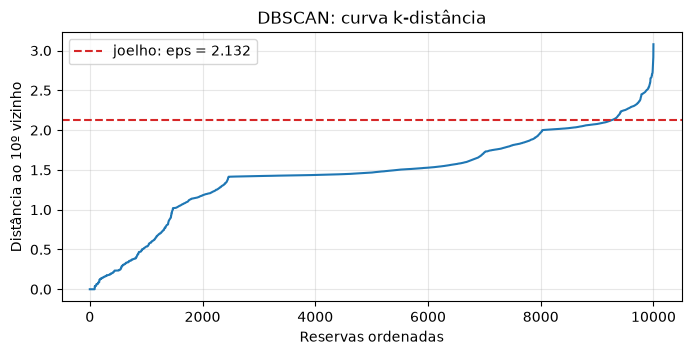

In [46]:
# Escala do DBSCAN na amostra

MIN_AMOSTRAS = 10

vizinhos = NearestNeighbors(
    n_neighbors=MIN_AMOSTRAS + 1,
    n_jobs=-1,
).fit(X_AMOSTRA)

curva = np.sort(
    vizinhos.kneighbors(X_AMOSTRA)[0][:, -1]
)

indice_joelho = cotovelo(
    np.arange(len(curva)),
    curva,
)

eps_joelho = (
    curva[int(indice_joelho)]
    if indice_joelho is not None
    else float(np.percentile(curva, 90))
)

raios = sorted(
    {
        round(float(np.percentile(curva, percentil)), 3)
        for percentil in (50, 70, 80, 90, 95)
    },
    reverse=True,
)

print(f"Amostra: {len(X_AMOSTRA):,}")
print(f"Raios: {raios}")
print(f"Eps do joelho: {eps_joelho:.3f}")

plt.figure(figsize=(8, 3.5))
plt.plot(curva)
plt.axhline(
    eps_joelho,
    color="tab:red",
    linestyle="--",
    label=f"joelho: eps = {eps_joelho:.3f}",
)
plt.title("DBSCAN: curva k-distância")
plt.xlabel("Reservas ordenadas")
plt.ylabel(f"Distância ao {MIN_AMOSTRAS}º vizinho")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [47]:
algoritmos = {
    "k-means": (K, ajustar_kmeans),
    "k-means manhattan": (
        K,
        lambda k: kmedianas(X_AMOSTRA, k, n_init=2, max_iter=30),
    ),
    "k-means mahalanobis": (K, ajustar_mahalanobis),
    "gmm": (K, ajustar_gmm),
    "dbscan": (raios, ajustar_dbscan),
}

POR_PARAMETRO = {"dbscan"}

## 4 · Varredura

In [48]:
linhas = []

for nome, (valores, ajustar) in algoritmos.items():
    inicio_algoritmo = time.perf_counter()

    for valor in valores:
        inicio = time.perf_counter()
        rotulos, peso = ajustar(valor)
        validos = rotulos >= 0
        rotulos_validos = rotulos[validos]
        grupos = len(np.unique(rotulos_validos))

        linhas.append(
            {
                "algoritmo": nome,
                "valor": valor,
                "grupos": grupos,
                "peso": float(peso),
                "silhueta": silhueta(X_AMOSTRA, rotulos),
                "maior_grupo": (
                    np.bincount(rotulos_validos).max() / len(rotulos_validos)
                    if validos.any()
                    else np.nan
                ),
                "ruido": 1 - validos.mean(),
                "segundos": time.perf_counter() - inicio,
            }
        )

    print(f"{nome}: {time.perf_counter() - inicio_algoritmo:.1f}s")

varredura = pd.DataFrame(linhas)

print(f"Configurações avaliadas: {len(varredura)}")
varredura

k-means: 24.4s
k-means manhattan: 17.8s
k-means mahalanobis: 33.7s
gmm: 62.0s
dbscan: 23.6s
Configurações avaliadas: 25


,algoritmo,valor,grupos,peso,silhueta,maior_grupo,ruido,segundos
0,k-means,1.000,1,5.887160e+04,NaN,1.000000,0.0000,0.287394
1,k-means,2.000,2,5.263313e+04,0.124796,0.635300,0.0000,6.653102
2,k-means,3.000,3,4.863813e+04,0.088697,0.375700,0.0000,6.002317
3,k-means,4.000,4,4.617437e+04,0.097938,0.290500,0.0000,6.160831
4,k-means,5.000,5,4.298222e+04,0.124434,0.274200,0.0000,5.344044
5,k-means manhattan,1.000,1,8.239737e+04,NaN,1.000000,0.0000,0.120658
6,k-means manhattan,2.000,2,7.338828e+04,0.101114,0.689600,0.0000,4.206114
7,k-means manhattan,3.000,3,6.852406e+04,0.082227,0.455600,0.0000,4.430238
8,k-means manhattan,4.000,4,6.476963e+04,0.092165,0.381600,0.0000,4.111080
9,k-means manhattan,5.000,5,6.197538e+04,0.104077,0.344900,0.0000,4.913244


In [49]:
def resumir(t):
    t = t.set_index("valor")
    cotovelo_valor = cotovelo(t.index, t["peso"])
    melhor_valor = (
        t["silhueta"].idxmax()
        if t["silhueta"].notna().any()
        else None
    )

    return pd.Series(
        {
            "cotovelo": cotovelo_valor,
            "melhor": melhor_valor,
            "k no cotovelo": (
                t.loc[cotovelo_valor, "grupos"]
                if cotovelo_valor is not None
                else np.nan
            ),
            "silhueta no cotovelo": (
                t.loc[cotovelo_valor, "silhueta"]
                if cotovelo_valor is not None
                else np.nan
            ),
            "k de maior silhueta": (
                t.loc[melhor_valor, "grupos"]
                if melhor_valor is not None
                else np.nan
            ),
            "maior silhueta": (
                t.loc[melhor_valor, "silhueta"]
                if melhor_valor is not None
                else np.nan
            ),
            "maior grupo": (
                t.loc[melhor_valor, "maior_grupo"]
                if melhor_valor is not None
                else np.nan
            ),
            "ruído": (
                t.loc[melhor_valor, "ruido"]
                if melhor_valor is not None
                else np.nan
            ),
            "tempo (s)": t["segundos"].sum(),
        }
    )


resumo = varredura.groupby("algoritmo", sort=False).apply(resumir)

## 5 · Peso × silhueta de cada algoritmo

Como ler cada painel:
* a **linha tracejada** marca o cotovelo do peso;
* a **estrela** marca a maior silhueta;
* a **faixa verde** é o número de grupos que o negócio opera;
* a **linha pontilhada** é a silhueta mínima.

Quando cotovelo e estrela coincidem, as duas leituras concordam.

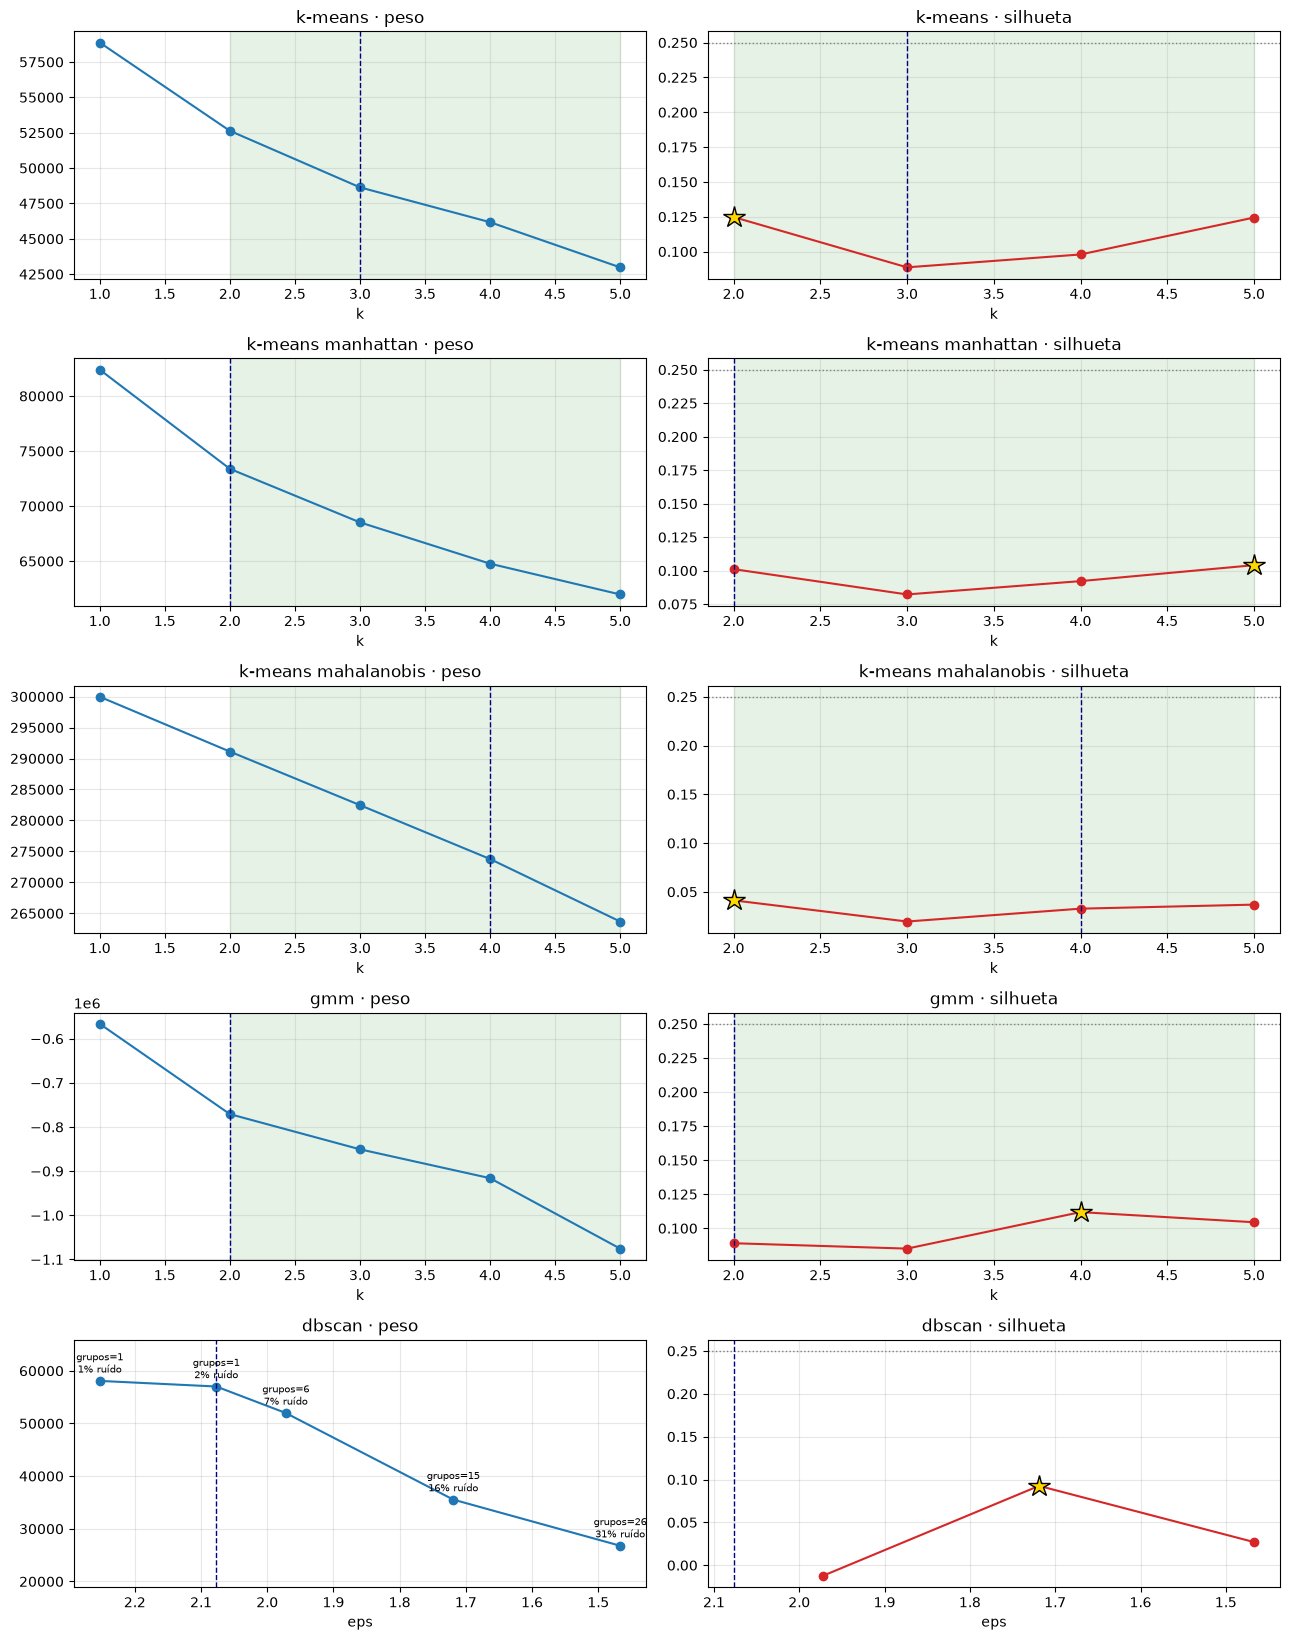

In [50]:
fig, eixos = plt.subplots(
    len(algoritmos),
    2,
    figsize=(13, 3.3 * len(algoritmos)),
)

for (ax_peso, ax_sil), (nome, t) in zip(
    eixos,
    varredura.groupby("algoritmo", sort=False),
):
    c, m = resumo.loc[nome, ["cotovelo", "melhor"]]
    ax_peso.plot(t["valor"], t["peso"], "o-")
    ax_sil.plot(t["valor"], t["silhueta"], "o-", color="tab:red")
    ax_sil.axhline(SILHUETA_MINIMA, color="gray", ls=":", lw=1)

    if pd.notna(m):
        ax_sil.plot(
            m,
            t.set_index("valor").loc[m, "silhueta"],
            "*",
            ms=16,
            color="gold",
            mec="black",
        )

    for ax in (ax_peso, ax_sil):
        ax.grid(alpha=0.3)
        if pd.notna(c):
            ax.axvline(c, color="navy", ls="--", lw=1)
        if nome in POR_PARAMETRO:
            ax.invert_xaxis()
        else:
            ax.axvspan(*FAIXA, color="green", alpha=0.1)

    if nome in POR_PARAMETRO:
        for x, y, g, r in zip(
            t["valor"],
            t["peso"],
            t["grupos"],
            t["ruido"],
        ):
            ax_peso.annotate(
                f"grupos={g}" + (f"\n{r:.0%} ruído" if r else ""),
                (x, y),
                textcoords="offset points",
                xytext=(0, 6),
                ha="center",
                fontsize=7,
            )
        ax_peso.margins(y=0.25)

    rotulo_x = "eps" if nome == "dbscan" else "k"
    ax_peso.set(title=f"{nome} · peso", xlabel=rotulo_x)
    ax_sil.set(title=f"{nome} · silhueta", xlabel=rotulo_x)

fig.tight_layout()
plt.show()

## 6 · Comparativo

In [51]:
(resumo.drop(columns=["cotovelo", "melhor"])
 .style.format(precision=3, na_rep="—")
 .format(
     {
         "k no cotovelo": "{:.0f}",
         "k de maior silhueta": "{:.0f}",
         "maior grupo": "{:.1%}",
         "ruído": "{:.1%}",
         "tempo (s)": "{:.1f}",
     },
     na_rep="—",
 )
 .highlight_max(subset=["maior silhueta"], color="#d8f3dc"))

,k no cotovelo,silhueta no cotovelo,k de maior silhueta,maior silhueta,maior grupo,ruído,tempo (s)
algoritmo,,,,,,,
k-means,3,0.088697,2,0.124796,63.5%,0.0%,24.4
k-means manhattan,2,0.101114,5,0.104077,34.5%,0.0%,17.8
k-means mahalanobis,4,0.032767,2,0.041299,84.1%,0.0%,33.7
gmm,2,0.089043,4,0.111867,43.5%,0.0%,62.0
dbscan,1,—,15,0.092572,71.1%,16.4%,23.6


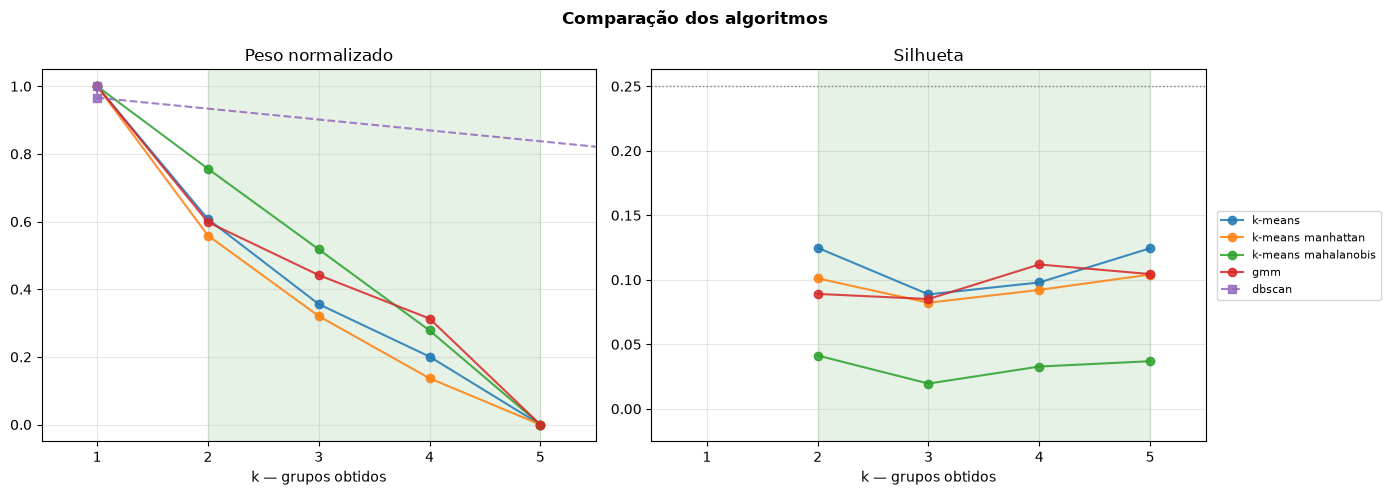

In [52]:
fig, (ax_peso, ax_sil) = plt.subplots(1, 2, figsize=(14, 5))

for nome, t in varredura.groupby("algoritmo", sort=False):
    t = t.sort_values("grupos")
    estilo = "s--" if nome in POR_PARAMETRO else "o-"
    peso_norm = (t["peso"] - t["peso"].min()) / (
        t["peso"].max() - t["peso"].min()
    )
    ax_peso.plot(t["grupos"], peso_norm, estilo, label=nome, alpha=0.85)
    ax_sil.plot(
        t["grupos"],
        t["silhueta"],
        estilo,
        label=nome,
        alpha=0.85,
    )

for ax in (ax_peso, ax_sil):
    ax.axvspan(*FAIXA, color="green", alpha=0.1)
    ax.set(xlabel="k — grupos obtidos", xlim=(0.5, K[-1] + 0.5))
    ax.grid(alpha=0.3)

ax_sil.axhline(SILHUETA_MINIMA, color="gray", ls=":", lw=1)
ax_peso.set_title("Peso normalizado")
ax_sil.set_title("Silhueta")
ax_sil.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.suptitle("Comparação dos algoritmos", fontweight="bold")
fig.tight_layout()
plt.show()

## 7 · A escolha

Regra declarada antes de olhar o resultado:
1. *k* dentro da faixa que o negócio opera;
2. ruído até o teto e nenhum grupo com mais de 90% da carteira;
3. entre os que sobram, vence a maior **silhueta comum**. Abaixo da silhueta mínima, o vencedor sai com a ressalva de que a estrutura é fraca.

In [53]:
aprovados = (
    varredura
    .query("@FAIXA[0] <= grupos <= @FAIXA[1]")
    .query("ruido <= @RUIDO_MAXIMO")
    .query("maior_grupo <= @GRUPO_MAXIMO")
    .dropna(subset=["silhueta"])
    .sort_values("silhueta", ascending=False)
)

print(
    f"{len(aprovados)} de {len(varredura)} configurações passam na regra. "
    f"Sem nenhuma aprovada: "
    f"{sorted(set(varredura.algoritmo) - set(aprovados.algoritmo)) or 'nenhum'}"
)

display(
    aprovados.head(10)
    .style.hide(axis="index")
    .format(precision=3)
    .format(
        {
            "maior_grupo": "{:.1%}",
            "ruido": "{:.1%}",
            "peso": "{:,.1f}",
            "segundos": "{:.1f}",
        }
    )
)

vencedor = aprovados.iloc[0]
ressalva = (
    ""
    if vencedor["silhueta"] >= SILHUETA_MINIMA
    else " (abaixo da silhueta mínima: estrutura fraca)"
)
print(
    f"Vencedor: {vencedor['algoritmo']} com k = {vencedor['grupos']} "
    f"· silhueta {vencedor['silhueta']:.3f}{ressalva}"
)

16 de 25 configurações passam na regra. Sem nenhuma aprovada: ['dbscan']


algoritmo,valor,grupos,peso,silhueta,maior_grupo,ruido,segundos
k-means,2.000000,2,"52,633.1",0.124796,63.5%,0.0%,6.7
k-means,5.000000,5,"42,982.2",0.124434,27.4%,0.0%,5.3
gmm,4.000000,4,"-915,932.4",0.111867,43.5%,0.0%,16.0
gmm,5.000000,5,"-1,075,463.9",0.104437,31.3%,0.0%,15.0
k-means manhattan,5.000000,5,"61,975.4",0.104077,34.5%,0.0%,4.9
k-means manhattan,2.000000,2,"73,388.3",0.101114,69.0%,0.0%,4.2
k-means,4.000000,4,"46,174.4",0.097938,29.0%,0.0%,6.2
k-means manhattan,4.000000,4,"64,769.6",0.092165,38.2%,0.0%,4.1
gmm,2.000000,2,"-770,850.4",0.089043,56.2%,0.0%,14.6
k-means,3.000000,3,"48,638.1",0.088697,37.6%,0.0%,6.0


Vencedor: k-means com k = 2 · silhueta 0.125 (abaixo da silhueta mínima: estrutura fraca)


## Como interpretar os resultados

- O peso tende a cair quando aumentamos a quantidade de grupos, mas sozinho não escolhe o melhor modelo.
- A silhueta ajuda a avaliar coesão e separação; valores baixos podem ocorrer em uma matriz com muitas variáveis one-hot.
- O DBSCAN depende da densidade e pode produzir um grupo dominante ou muito ruído.
- A escolha final deve considerar silhueta, tamanho dos grupos, percentual de ruído e utilidade para a operação hoteleira.
- Os resultados desta etapa são exploratórios; a avaliação final deve verificar cancelamento e estabilidade dos segmentos.